# <font color="blue"> $MÉTODO$ $DE$ $NEVILLE$

$El$ $algoritmo$ $de$ $Neville$ es un procedimiento matemático utilizado para la interpolación polinómica, específicamente diseñado para evaluar el valor de un polinomio interpolante en un punto dado (x).

Su principal utilididad radica en: 
Calculo eficiente de valores,Interpolación recursiva,Diferenciación numérica.

La $ecuación$ $matemática$ a usar es la siguiente:

$$P(x) = \frac {(x − x_j)P_{0,1,...,j−1,j+1,...,k} (x) − (x − x_i)P_{0,1,...,i−1,i+1,...,k} (x)}{x_i - x_j}$$

Para el Método de Neville se necesita tabular como en los siguientes ejemplos:

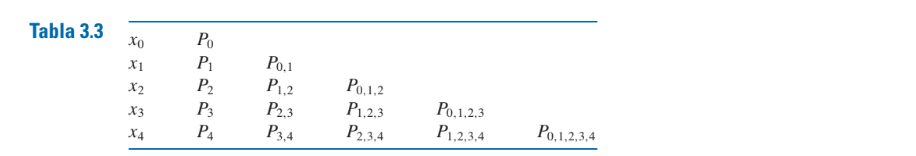

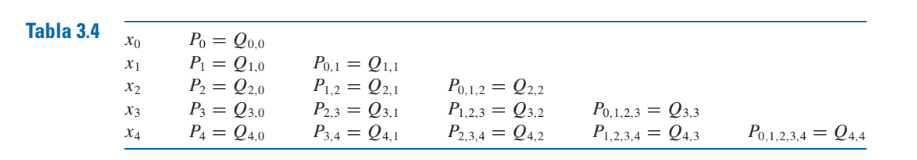


In [19]:
def interpolacion_neville(x_vals, y_vals, x_eval):

    n = len(x_vals) - 1
    # Inicializamos la matriz Q de tamaño (n+1)x(n+1) con ceros
    Q = [[0.0 for _ in range(n + 1)] for _ in range(n + 1)]
    
    # ENTRADA: La primera columna Q_{i,0} son los valores f(x_i)
    for i in range(n + 1):
        Q[i][0] = y_vals[i]
        
    # Iteración para construir la tabla
    for i in range(1, n + 1):
        for j in range(1, i + 1):

            term1 = (x_eval - x_vals[i - j]) * Q[i][j - 1]
            term2 = (x_eval - x_vals[i]) * Q[i - 1][j - 1]
            denominador = x_vals[i] - x_vals[i - j]
            
            Q[i][j] = (term1 - term2) / denominador
            
    return Q

In [20]:
def imprimir_tabla(x_vals, Q):
    
    print(f"{'x_i':<8} | {'f(x_i)':<12} | Tabla de Neville (Q)")
    print("-" * 75)
    
    for i in range(len(x_vals)):
        # Imprimimos el nodo x_i al inicio de la fila
        fila_str = f"{x_vals[i]:<8.1f} | "
        
        # Imprimimos los valores de la fila (j=0 hasta i)
        valores = [f"{Q[i][j]:.7f}" for j in range(i + 1)]
        
        # Unimos los valores con tabulaciones o espacios
        fila_str += "\t".join(valores)
        print(fila_str)


In [21]:
# COMPROBACIÓN 

x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_evaluar = 1.5

print(f"--- Aproximación de f({x_evaluar}) usando el método de Neville ---\n")

# Ejecutamos el algoritmo
tabla_Q = interpolacion_neville(x_datos, y_datos, x_evaluar)

# Mostramos la tabla 
imprimir_tabla(x_datos, tabla_Q)

print("\n--- Resultado Final ---")
# El resultado es Q_{n,n} (último elemento de la última fila)
n = len(x_datos) - 1
print(f"P({x_evaluar}) = Q_{n},{n} = {tabla_Q[n][n]:.7f}")

--- Aproximación de f(1.5) usando el método de Neville ---

x_i      | f(x_i)       | Tabla de Neville (Q)
---------------------------------------------------------------------------
1.0      | 0.7651977
1.3      | 0.6200860	0.5233449
1.6      | 0.4554022	0.5102968	0.5124715
1.9      | 0.2818186	0.5132634	0.5112857	0.5118127
2.2      | 0.1103623	0.5104270	0.5137361	0.5118302	0.5118200

--- Resultado Final ---
P(1.5) = Q_4,4 = 0.5118200
